**Pertanyaan:** apakah representasi yang peka konteks kalimat (transformer) menambah informasi dibanding lexicon dan embedding statis?

| Set | Fitur |
|---|---|
| **A** | 7 fitur kurs |
| **B** | A + 16 lexicon (VADER + LM) |
| **C-MiniLM** | A + embedding `all-MiniLM-L6-v2` (umum, 384d) → PCA |
| **C-FinBERT-emb** | A + embedding `ProsusAI/finbert` (domain keuangan, 768d) → PCA |
| **C-FinBERT-sent** | A + 6 skor sentimen FinBERT harian (pengganti VADER/LM yang peka konteks) |
| **B + FinBERT-sent** | A + lexicon + sentimen FinBERT |

Semua model transformer dipakai **beku (frozen)**: tidak ada fine-tuning, jadi tidak ada fitting di data val/test. Scaler dan PCA tetap dilatih di train saja.

## 0. Setup

In [1]:
%pip install torch transformers

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
print("cwd      :", Path.cwd())
print("eval_utils:", Path("../src/eval_utils.py").resolve(), "| ada:", Path("../src/eval_utils.py").exists())
print("data/export ada:", Path("../data/export/articles.parquet").exists())

cwd      : /Users/farsyaant/nlpproject-baru/src/notebook
eval_utils: /Users/farsyaant/nlpproject-baru/src/src/eval_utils.py | ada: False
data/export ada: False


In [6]:
import sys, re, json, time, warnings
sys.dont_write_bytecode = True
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

warnings.filterwarnings("ignore")
sys.path.append("..")
from eval_utils import evaluate, naive_baselines

EXPORT_DIR = Path("../../data/export")
CACHE_DIR = Path("cache_embeddings"); CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
torch.set_num_threads(max(1, torch.get_num_threads()))
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("device:", DEVICE)

device: mps


## 1. Muat data dan split (sama seperti Bagian A)

In [7]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5", "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all()
for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"]
tr = (daily["split"] == "train").to_numpy(); va = (daily["split"] == "val").to_numpy(); te = (daily["split"] == "test").to_numpy()
y = daily["target"].to_numpy()

articles["split"] = articles["aligned_trading_date"].map(dict(zip(daily["date"], daily["split"])))
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
print("baris per split:", tr.sum(), va.sum(), te.sum())
print(articles["split"].value_counts(dropna=False).to_string())

baris per split: 836 178 180
split
train    2489
test     1220
val       619
NaN         4


## 2. Ekstraksi embedding dengan chunking

Transformer punya batas panjang input (MiniLM dilatih di 256 token, FinBERT maks 512), sedangkan artikel rata-rata ~800 kata (~1.000 token). Kalau hanya dipotong, **sebagian besar isi artikel hilang**.

Strategi di sini: pecah artikel jadi **chunk berbasis kata**, encode tiap chunk, **L2-normalisasi**, lalu **rata-rata chunk** jadi vektor artikel. Jumlah chunk dibatasi (`max_chunks`) agar waktu terkendali. Judul ada di awal chunk pertama.

Pooling: **rata-rata token** dari layer terakhir (dengan attention mask). Untuk FinBERT, satu forward pass juga menghasilkan probabilitas sentimen (positive/negative/neutral).

In [8]:
MODEL_CFG = {
    "MiniLM":  dict(name="sentence-transformers/all-MiniLM-L6-v2", chunk_words=160, max_chunks=5, max_len=256, batch=32, logits=False),
    "FinBERT": dict(name="ProsusAI/finbert", chunk_words=300, max_chunks=2, max_len=512, batch=16, logits=True),
    # opsional (matikan/hidupkan): RoBERTa mentah bukan model kalimat, mean-pooling-nya biasanya lemah
    # "RoBERTa": dict(name="roberta-base", chunk_words=300, max_chunks=2, max_len=512, batch=16, logits=False),
}

def make_chunks(text, chunk_words, max_chunks):
    w = text.split()
    ch = [" ".join(w[i:i + chunk_words]) for i in range(0, len(w), chunk_words)][:max_chunks]
    return ch or [""]

# cakupan: berapa persen kata artikel yang ikut ter-encode
n_words = articles["text_raw"].str.split().map(len)
for k, c in MODEL_CFG.items():
    cov = np.minimum(n_words, c["chunk_words"] * c["max_chunks"]).sum() / n_words.sum()
    n_ch = sum(len(make_chunks(t, c["chunk_words"], c["max_chunks"])) for t in articles["text_raw"])
    print(f"{k:8s} chunk={c['chunk_words']} kata x maks {c['max_chunks']} | cakupan kata artikel {cov:.1%} | total chunk {n_ch:,}")

MiniLM   chunk=160 kata x maks 5 | cakupan kata artikel 83.6% | total chunk 19,034
FinBERT  chunk=300 kata x maks 2 | cakupan kata artikel 70.8% | total chunk 8,664


In [9]:
@torch.no_grad()
def encode_chunks(chunks, cfg):
    tok = AutoTokenizer.from_pretrained(cfg["name"])
    Cls = AutoModelForSequenceClassification if cfg["logits"] else AutoModel
    model = Cls.from_pretrained(cfg["name"]).to(DEVICE).eval()
    order = np.argsort([len(c) for c in chunks])               # urut panjang → padding hemat
    H = np.zeros((len(chunks), model.config.hidden_size), np.float32)
    P = np.zeros((len(chunks), model.config.num_labels), np.float32) if cfg["logits"] else None
    n_trunc = 0; t0 = time.time()
    for b in range(0, len(order), cfg["batch"]):
        idx = order[b:b + cfg["batch"]]
        enc = tok([chunks[i] for i in idx], padding=True, truncation=True,
                  max_length=cfg["max_len"], return_tensors="pt")
        n_trunc += int((enc["attention_mask"].sum(1) >= cfg["max_len"]).sum())
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        if cfg["logits"]:
            out = model(**enc, output_hidden_states=True)
            hs = out.hidden_states[-1]; P[idx] = torch.softmax(out.logits, -1).float().cpu().numpy()
        else:
            hs = model(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).to(hs.dtype)
        H[idx] = ((hs * m).sum(1) / m.sum(1)).float().cpu().numpy()
        if (b // cfg["batch"]) % 50 == 0:
            done = b + len(idx); el = time.time() - t0
            print(f"  {done}/{len(order)} chunk | {el:.0f}s | sisa ~{el / done * (len(order) - done):.0f}s", flush=True)
    labels = {int(k): v.lower() for k, v in model.config.id2label.items()} if cfg["logits"] else None
    return H, P, labels, n_trunc / len(chunks)

def embed_articles(tag):
    cfg = MODEL_CFG[tag]
    f = CACHE_DIR / f"{tag}_cw{cfg['chunk_words']}_mc{cfg['max_chunks']}_ml{cfg['max_len']}.npz"
    if f.exists():
        z = np.load(f, allow_pickle=True); print(f"{tag}: dimuat dari cache {f.name}")
        return z["A"], (z["P"] if cfg["logits"] else None), (z["labels"].item() if cfg["logits"] else None)
    chunks, owner = [], []
    for i, t in enumerate(articles["text_raw"]):
        c = make_chunks(t, cfg["chunk_words"], cfg["max_chunks"]); chunks += c; owner += [i] * len(c)
    owner = np.array(owner)
    print(f"{tag}: encode {len(chunks):,} chunk di {DEVICE} ...")
    H, P, labels, trunc = encode_chunks(chunks, cfg)
    print(f"{tag}: chunk yang masih terpotong max_len = {trunc:.1%}")
    H = H / np.linalg.norm(H, axis=1, keepdims=True).clip(1e-12)              # L2 per chunk
    A = pd.DataFrame(H).groupby(owner).mean().to_numpy()                       # rata-rata chunk → artikel
    Pa = pd.DataFrame(P).groupby(owner).mean().to_numpy() if cfg["logits"] else np.zeros((len(A), 1))
    np.savez(f, A=A, P=Pa, labels=np.array(labels, dtype=object))
    return A, (Pa if cfg["logits"] else None), labels

EMB = {}
for tag in MODEL_CFG:
    EMB[tag] = embed_articles(tag)
    print(tag, "→ matriks artikel", EMB[tag][0].shape)

MiniLM: encode 19,034 chunk di mps ...
  32/19034 chunk | 0s | sisa ~285s
  1632/19034 chunk | 4s | sisa ~47s
  3232/19034 chunk | 11s | sisa ~54s
  4832/19034 chunk | 18s | sisa ~53s
  6432/19034 chunk | 25s | sisa ~50s
  8032/19034 chunk | 32s | sisa ~44s
  9632/19034 chunk | 39s | sisa ~38s
  11232/19034 chunk | 45s | sisa ~31s
  12832/19034 chunk | 52s | sisa ~25s
  14432/19034 chunk | 59s | sisa ~19s
  16032/19034 chunk | 66s | sisa ~12s
  17632/19034 chunk | 72s | sisa ~6s
MiniLM: chunk yang masih terpotong max_len = 1.7%
MiniLM → matriks artikel (4332, 384)
FinBERT: dimuat dari cache FinBERT_cw300_mc2_ml512.npz
FinBERT → matriks artikel (4332, 768)


Cek kewarasan: artikel yang mirip topiknya harus berdekatan (cosine). Kita ambil satu artikel acak dan lihat 3 tetangganya.

In [10]:
rng = np.random.default_rng(SEED)
i = int(rng.integers(len(articles)))
print("QUERY:", articles.loc[i, "title"])
for tag in EMB:
    A = EMB[tag][0]; An = A / np.linalg.norm(A, axis=1, keepdims=True).clip(1e-12)
    nn = np.argsort(-(An @ An[i]))[1:4]
    print(f"== {tag}")
    for j in nn: print("   -", articles.loc[j, "title"][:110])

QUERY: Kraken crypto exchange won’t shut down Russian accounts unless legally required, CEO says
== MiniLM
   - The Russia-Ukraineconflicthas thrust crypto into the spotlight and raised 3 big questions
   - ‘We will come and we will find you’: U.S. issues warning to anyone helping Russia ...
   - Bitcoin jumps as Russia-Ukraineconflictcontinues and U.S. imposes further sanctions
== FinBERT
   - Why Russian people need tech companies to stay, not withdraw: It’s terrifying ’how dark that ...
   - Why Meta, X and TikTok face more pressure from Europe than the U.S. on Israel-Hamas ...
   - Polymarket removes wagers on U.S. service member rescue mission in Iran


## 3. Artikel → hari → fitur

Sama seperti Bagian A: rata-rata per `aligned_trading_date`, hari tanpa berita = vektor netral (0 di ruang PCA), PCA 20 komponen **di-fit pada hari train yang punya berita**, pakai k = 5/10/20 komponen pertama.

Sentimen FinBERT harian (6 fitur): rata-rata P(positive), P(negative), P(neutral), serta rata-rata/min/max "net" = P(pos) − P(neg). Hari tanpa berita diisi 0 (sama dengan perlakuan lexicon di Tugas 2).

In [11]:
KS = (5, 10, 20)

def pca_daily(A, kmax=max(KS)):
    keep = articles["split"].notna().to_numpy()
    emb = pd.DataFrame(A[keep]); emb["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    d = emb.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); D = d.to_numpy(dtype=float)
    pca = PCA(n_components=kmax, random_state=SEED).fit(D[tr & has])        # TRAIN saja
    Z = np.zeros((len(daily), kmax)); Z[has] = pca.transform(D[has])
    return {k: Z[:, :k] for k in KS}, int(has.sum()), float(pca.explained_variance_ratio_.sum())

def finbert_daily(P, labels):
    idx = {v: k for k, v in labels.items()}
    pos, neg, neu = P[:, idx["positive"]], P[:, idx["negative"]], P[:, idx["neutral"]]
    keep = articles["split"].notna().to_numpy()
    df = pd.DataFrame({"fb_pos": pos, "fb_neg": neg, "fb_neu": neu, "net": pos - neg})[keep]
    df["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    g = df.groupby("date")
    out = pd.DataFrame({"fb_pos_mean": g["fb_pos"].mean(), "fb_neg_mean": g["fb_neg"].mean(),
                        "fb_neu_mean": g["fb_neu"].mean(), "fb_net_mean": g["net"].mean(),
                        "fb_net_min": g["net"].min(), "fb_net_max": g["net"].max()})
    return out.reindex(daily["date"]).fillna(0.0).to_numpy()

FEATS = {}      # nama set -> matriks fitur teks (tanpa kurs)
INFO = []
for tag in EMB:
    Zs, n_days, evr = pca_daily(EMB[tag][0])
    for k, Z in Zs.items():
        FEATS[f"C  kurs+{tag}-emb k={k}"] = Z
    INFO.append(dict(model=tag, hari_ada_berita=n_days, EVR_20_komponen=round(evr, 3)))
FB_SENT = finbert_daily(*[EMB["FinBERT"][1], EMB["FinBERT"][2]])
pd.DataFrame(INFO)

,model,hari_ada_berita,EVR_20_komponen
0,MiniLM,1073,0.606
1,FinBERT,1073,0.795


## 4. Protokol evaluasi (identik dengan Bagian A)

Scaler & model dilatih di train; skor dilaporkan di val dan test; perbandingan utama memakai val. Ridge, Random Forest, Gradient Boosting dengan hyperparameter tetap; RF/GB dirata-ratakan atas 3 seed. Pembanding tanpa model: Prediksi 0, Return kemarin, Konstan (rata-rata target train).

In [12]:
MODELS = {
    "Ridge": lambda s: Ridge(alpha=10.0),
    "RandForest": lambda s: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=s),
    "GradBoost": lambda s: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=s),
}
SEEDS = (0, 1, 2)

def direction_metrics(y_true, y_pred):
    m = y_true != 0
    t, p = y_true[m] > 0, y_pred[m] > 0
    return {"BalAcc": balanced_accuracy_score(t, p), "MCC": matthews_corrcoef(t, p)}

def fit_predict(X):
    Xs = StandardScaler().fit(X[tr]).transform(X)
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    return preds

rows = []
def run(set_name, X):
    for mname, p in fit_predict(X).items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))

ret_today = daily["ret"].to_numpy(); base_rows = []
for sp, mask in (("val", va), ("test", te)):
    nb = naive_baselines(y[mask], ret_today[mask])
    nb["Konstan (mean train)"] = evaluate(y[mask], np.full(mask.sum(), y[tr].mean()))
    preds = {"Prediksi 0": np.zeros(mask.sum()), "Return kemarin": ret_today[mask],
             "Konstan (mean train)": np.full(mask.sum(), y[tr].mean())}
    for name, r in nb.items():
        r = dict(r); r.update(direction_metrics(y[mask], preds[name]))
        base_rows.append(dict(set=name, model="-", split=sp, **r))

KURS = daily[KURS_COLS].to_numpy(); LEX = daily[LEX_COLS].to_numpy()
run("A  kurs", KURS)
run("B  kurs+lexicon", np.hstack([KURS, LEX]))
for name, Z in FEATS.items():
    run(name, np.hstack([KURS, Z]))
run("C  kurs+FinBERT-sent", np.hstack([KURS, FB_SENT]))
run("B+ kurs+lexicon+FinBERT-sent", np.hstack([KURS, LEX, FB_SENT]))

res = pd.DataFrame(rows); base = pd.DataFrame(base_rows)
print("selesai:", res["set"].nunique(), "set x", res["model"].nunique(), "model")

selesai: 10 set x 3 model


## 5. Hasil

### 5.1 Pembanding tanpa model

In [13]:
cols = ["MAE", "RMSE", "DirAcc", "BalAcc", "MCC"]
base.pivot(index="set", columns="split", values=cols).round(5)

MAE              RMSE            DirAcc          BalAcc               MCC         
split                    test      val     test      val     test      val   test      val     test      val
set                                                                                                         
Konstan (mean train)  0.00218  0.00246  0.00289  0.00338  0.59091  0.53409  0.500  0.50000  0.00000  0.00000
Prediksi 0            0.00221  0.00247  0.00291  0.00338  0.00000  0.00000  0.500  0.50000  0.00000  0.00000
Return kemarin        0.00308  0.00347  0.00398  0.00461  0.54545  0.50568  0.539  0.50908  0.07754  0.01816

### 5.2 Rata-rata 3 model per set fitur
`dRMSE%` = selisih terhadap A pada split yang sama (negatif = lebih baik dari A).

In [14]:
mean_tbl = res.groupby(["set", "split"])[["RMSE", "DirAcc", "BalAcc", "MCC"]].mean().unstack("split")
a_rmse = mean_tbl.loc["A  kurs", "RMSE"]
for sp in ("val", "test"):
    mean_tbl[("dRMSE%", sp)] = (mean_tbl[("RMSE", sp)] / a_rmse[sp] - 1) * 100
mean_tbl = mean_tbl.sort_values(("RMSE", "val"))
mean_tbl.round(5)

RMSE            DirAcc            BalAcc               MCC            dRMSE%         
split                            test      val     test      val     test      val     test      val      val     test
set                                                                                                                   
C  kurs+FinBERT-emb k=10      0.00295  0.00341  0.48295  0.50758  0.52475  0.52681  0.04366  0.06447 -0.77822 -2.60402
C  kurs+FinBERT-emb k=20      0.00300  0.00341  0.46023  0.49621  0.50125  0.50865 -0.00096  0.01769 -0.70417 -0.82364
C  kurs+FinBERT-emb k=5       0.00300  0.00341  0.41477  0.48864  0.48486  0.50701 -0.04952  0.01545 -0.55603 -0.79602
C  kurs+MiniLM-emb k=20       0.00297  0.00342  0.45644  0.52083  0.50873  0.53300  0.01179  0.07120 -0.35585 -1.98838
C  kurs+MiniLM-emb k=5        0.00301  0.00343  0.47159  0.50947  0.52796  0.52443  0.05715  0.05664 -0.21866 -0.69946
C  kurs+MiniLM-emb k=10       0.00300  0.00343  0.45644  0.50758  0.51371  0.52474  0.01940  0.05904 -0.16511 -0.86932
C  kurs+FinBERT-sent          0.00303  0.00343  0.45076  0.48106  0.52101  0.50251  0.05447 -0.00515 -0.05899  0.10689
A  kurs                       0.00303  0.00343  0.40720  0.47159  0.49769  0.49728 -0.03028 -0.01454  0.00000  0.00000
B+ kurs+lexicon+FinBERT-sent  0.00301  0.00344  0.45644  0.46212  0.50730  0.48063  0.01169 -0.04433  0.12086 -0.45894
B  kurs+lexicon               0.00301  0.00346  0.44318  0.45644  0.49181  0.47557 -0.02755 -0.04702  0.62909 -0.47218

### 5.3 Per model (RMSE val)

In [15]:
pm = res[res["split"] == "val"].pivot(index="set", columns="model", values="RMSE")
pm["rata2"] = pm.mean(axis=1); pm.sort_values("rata2").round(6)

model,GradBoost,RandForest,Ridge,rata2
set,,,,
C kurs+FinBERT-emb k=10,0.003399,0.003433,0.003390,0.003407
C kurs+FinBERT-emb k=20,0.003403,0.003432,0.003394,0.003410
C kurs+FinBERT-emb k=5,0.003416,0.003446,0.003382,0.003415
C kurs+MiniLM-emb k=20,0.003410,0.003468,0.003387,0.003422
C kurs+MiniLM-emb k=5,0.003438,0.003463,0.003379,0.003426
C kurs+MiniLM-emb k=10,0.003425,0.003472,0.003388,0.003428
C kurs+FinBERT-sent,0.003409,0.003503,0.003384,0.003432
A kurs,0.003421,0.003493,0.003388,0.003434
B+ kurs+lexicon+FinBERT-sent,0.003433,0.003472,0.003409,0.003438


### 5.4 Grafik

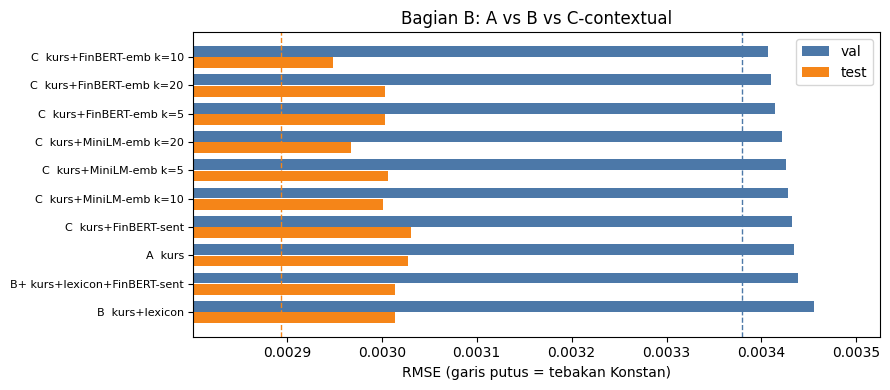

In [16]:
plot_df = mean_tbl["RMSE"].sort_values("val", ascending=False)
const = base[base["set"] == "Konstan (mean train)"].set_index("split")["RMSE"]
fig, ax = plt.subplots(figsize=(9, max(4, 0.34 * len(plot_df))))
yy = np.arange(len(plot_df))
ax.barh(yy + 0.2, plot_df["val"], height=0.38, label="val", color="#4C78A8")
ax.barh(yy - 0.2, plot_df["test"], height=0.38, label="test", color="#F58518")
ax.axvline(const["val"], color="#4C78A8", ls="--", lw=1); ax.axvline(const["test"], color="#F58518", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=8)
ax.set_xlim(plot_df.min().min() * 0.95, plot_df.max().max() * 1.02)
ax.set_xlabel("RMSE (garis putus = tebakan Konstan)"); ax.legend()
ax.set_title("Bagian B: A vs B vs C-contextual"); plt.tight_layout(); plt.show()

## 6. Acuan dari Bagian A (static), hasil run sebelumnya

RMSE rata-rata 3 model (val / test): A 0,00343 / 0,00303; B 0,00345 / 0,00301; C-static terbaik di val (FastText-idf k=20) 0,00339 / 0,00301; Konstan 0,00338 / 0,00289. Semua selisih antar set < 1,7%, dan tidak ada model yang mengalahkan Konstan.

(Angka ini diketik manual dari Bagian A. Kalau data atau protokol berubah, jalankan ulang Bagian A.)

## 7. Catatan metodologi

- **Tidak ada kebocoran:** model transformer beku (tanpa fine-tuning). Scaler dan PCA hanya di-fit di train. Meng-encode artikel val/test aman karena tidak ada parameter yang dipelajari dari mereka.
- **Chunking & cakupan:** lihat sel cakupan di bagian 2. Chunk yang masih terpotong `max_len` dilaporkan saat encoding.
- **Mean-pooling bukan satu-satunya pilihan.** MiniLM memang dilatih dengan mean-pooling. Untuk FinBERT/RoBERTa pooling CLS atau mean sama-sama lazim.
- **FinBERT-sent** adalah analogi VADER/LM yang peka konteks, jadi pembandingnya yang paling adil adalah B.
- Selisih < 1-2% anggap noise kecuali konsisten di val, test, dan ketiga model.

## 8. Kesimpulan 
1. Apakah ada set contextual yang konsisten lebih baik dari A dan B di val **dan** test? Berapa dRMSE%?
Keenam set embedding (FinBERT dan MiniLM, k=5/10/20) lebih rendah dari A di kedua split. Besarnya kecil:

Val: −0,17% sampai −0,78%.
Test: −0,70% sampai −2,60%. Yang terbesar FinBERT k=10 (−2,60%).

Terhadap B, embedding umumnya sedikit lebih baik. Tapi keenam set ini memakai data yang sama, jadi bukan enam bukti independen. Gain sekecil ini belum bisa dibedakan dari noise.

2. FinBERT (domain keuangan) vs MiniLM (umum): mana yang lebih baik? Embedding penuh atau hanya skor sentimen?
FinBERT-emb sedikit lebih baik di val di setiap k (rata-rata 0,003407–0,003415 vs MiniLM 0,003422–0,003428), dan di test hampir sama. Selisihnya sekitar 0,3–0,6%.
Skor sentimen FinBERT tidak membantu: FinBERT-sent −0,06% / +0,11% terhadap A, dan B+FinBERT-sent tidak lebih baik dari B. Kalau ada informasi, ia ada di embedding penuh, bukan di skor sentimen.

3. Apakah ada set yang mengalahkan baris Konstan? Bagaimana BalAcc/MCC?
Tidak. Konstan val 0,00338 dan test 0,00289. Terbaik di val 0,003407 dan di test 0,00295, jadi masih di atas (sekitar 0,8% dan 2%). BalAcc dan MCC mendekati 0,5 / 0. Yang tampak bagus (FinBERT k=10: BalAcc 0,527/0,525, MCC 0,064/0,044) masih dalam galat baku MCC sekitar 0,07, dan FinBERT k=20 di test MCC-nya −0,001. Hasilnya tidak stabil antar k.

4. Dibanding Bagian A (static), apakah konteks kalimat menambah sesuatu?
Setara. Terbaik static: val −1,39%, test −1,66%. Contextual: val −0,78%, test −2,60%. Di val static sedikit lebih unggul, di test contextual. Tidak ada bukti konteks kalimat menambah nilai.

5. Berdasarkan ini, apa yang diuji di Bagian berikutnya (fusion, fine-tuning)?